In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

In [191]:
url_listings = "https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-09-17/visualisations/listings.csv"
url_listings_det = "https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-09-17/data/listings.csv.gz"

listings = pd.read_csv(url_listings)
listings_det = pd.read_csv(url_listings_det, compression="gzip")

In [192]:
listings.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,23203785,"Apartamentos de Simone, Apartamento Picasso",16177101,1462596901119084538,Simone,Centro,Sol,40.419064,-3.704552,Entire home/apt,365.0,4.0,50,2025-04-28,0.38,5,0,0,NaN
1,23205290,Hermosilla III by Home at Homes,9228673,1462568646073234369,Home At Homes,Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,47,2025-11-18,0.45,4,83,2,Spain - National registration number<br />ESFC...
2,23216406,"Luminoso apartamento centro de Madrid, Atocha",61810218,1466760326474610119,Isabel,Centro,Embajadores,40.406210,-3.702160,Entire home/apt,NaN,2.0,30,2019-12-08,0.29,1,0,0,NaN
3,23226721,Céntrico y Cómodo Estudio en Atocha-Retiro WIFI,172793556,1468677043271793162,Máximo,Centro,Embajadores,40.406330,-3.698371,Entire home/apt,67.0,28.0,47,2026-06-20,0.45,1,131,3,Spain - National registration number<br />ESFC...
4,23243363,Luxury 100 sqm roof terrace apt. Best location.,229284,1462513244142164812,Luis,Chamberí,Arapiles,40.430090,-3.705720,Entire home/apt,350.0,7.0,3,2025-04-19,0.06,1,41,0,NaN


In [193]:
listings.columns

Index(['id', 'name', 'host_id', 'host_profile_id', 'host_name',
       'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'last_review', 'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='str')

In [194]:
listings_det.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
       'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months',
       'host_location', 'host_about', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
       'host_listings_count', 'host_total_listings_count',
       'host_verifications', 'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'price_quote_checkin_date', 'price_quote_c

In [195]:
listings.columns

Index(['id', 'name', 'host_id', 'host_profile_id', 'host_name',
       'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'last_review', 'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='str')

In [196]:
a_eliminar = ['host_id', 'host_profile_id', 'host_name', 'number_of_reviews',
              'last_review', 'reviews_per_month', 'calculated_host_listings_count',
              'number_of_reviews_ltm', 'license']

# eliminar columnas de listings
listings = listings.drop(columns=a_eliminar)

In [197]:
listings.head()

,id,name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,availability_365
0,23203785,"Apartamentos de Simone, Apartamento Picasso",Centro,Sol,40.419064,-3.704552,Entire home/apt,365.0,4.0,0
1,23205290,Hermosilla III by Home at Homes,Salamanca,Recoletos,40.425290,-3.683830,Entire home/apt,387.0,7.0,83
2,23216406,"Luminoso apartamento centro de Madrid, Atocha",Centro,Embajadores,40.406210,-3.702160,Entire home/apt,NaN,2.0,0
3,23226721,Céntrico y Cómodo Estudio en Atocha-Retiro WIFI,Centro,Embajadores,40.406330,-3.698371,Entire home/apt,67.0,28.0,131
4,23243363,Luxury 100 sqm roof terrace apt. Best location.,Chamberí,Arapiles,40.430090,-3.705720,Entire home/apt,350.0,7.0,41


In [198]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 23109 entries, 0 to 23108
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   23109 non-null  int64  
 1   name                 23109 non-null  str    
 2   neighbourhood_group  23109 non-null  str    
 3   neighbourhood        23109 non-null  str    
 4   latitude             23109 non-null  float64
 5   longitude            23109 non-null  float64
 6   room_type            23109 non-null  str    
 7   price                18785 non-null  float64
 8   minimum_nights       21380 non-null  float64
 9   availability_365     23109 non-null  int64  
dtypes: float64(4), int64(2), str(4)
memory usage: 1.8 MB


In [199]:
# analisis de nulos
listings.isnull().sum()

id                        0
name                      0
neighbourhood_group       0
neighbourhood             0
latitude                  0
longitude                 0
room_type                 0
price                  4324
minimum_nights         1729
availability_365          0
dtype: int64

In [200]:
#eliminar filas con nulos
listings = listings.dropna()

In [201]:
#cantidad de duplicados
listings.duplicated().sum()

np.int64(0)

## Análisis categórico

In [202]:
columnas_string = listings.select_dtypes(include=["object", "string"]).columns

value_counts_string = {
    columna: listings[columna].value_counts()
    for columna in columnas_string
}

for columna, conteos in value_counts_string.items():
    print(f"\n{columna}")
    display(conteos.to_frame(name="frecuencia"))


name


,frecuencia
name,
Habitación en piso compartido,115
Housing Castellana by Sharing Co,33
Fantastic residence ``FUNWAY´´ north zone Madrid,18
Great Studio,18
Habitación en Madrid,12
...,...
Luxury Atico en Madrid con Terraza privada,1
MyHouseSpain - Moderno piso en Chamberí,1
Sebastian Elcano calle en metro Embajadores,1



neighbourhood_group


,frecuencia
neighbourhood_group,
Centro,7294
Tetuán,1218
Salamanca,1174
Chamberí,1074
Arganzuela,856
Retiro,630
Chamartín,629
Ciudad Lineal,601
Carabanchel,546



neighbourhood


,frecuencia
neighbourhood,
Embajadores,1847
Universidad,1468
Palacio,1299
Sol,983
Justicia,887
...,...
Pavones,5
El Goloso,4
Fuentelareina,4



room_type


,frecuencia
room_type,
Entire home/apt,12160
Private room,4959
Shared room,136
Hotel room,29


In [203]:
# eliminar los registros donde room_type sea "Hotel room"
listings = listings[listings['room_type'] != 'Hotel room']

## Análisis Numérico

In [204]:
listings[['price', 'minimum_nights', 'availability_365']].describe().T

,count,mean,std,min,25%,50%,75%,max
price,17255.0,209.866010,565.760101,9.0,92.5,150.0,224.0,36883.0
minimum_nights,17255.0,7.551029,16.064379,1.0,1.0,2.0,4.0,365.0
availability_365,17255.0,203.394726,121.541271,0.0,86.0,236.0,317.0,365.0


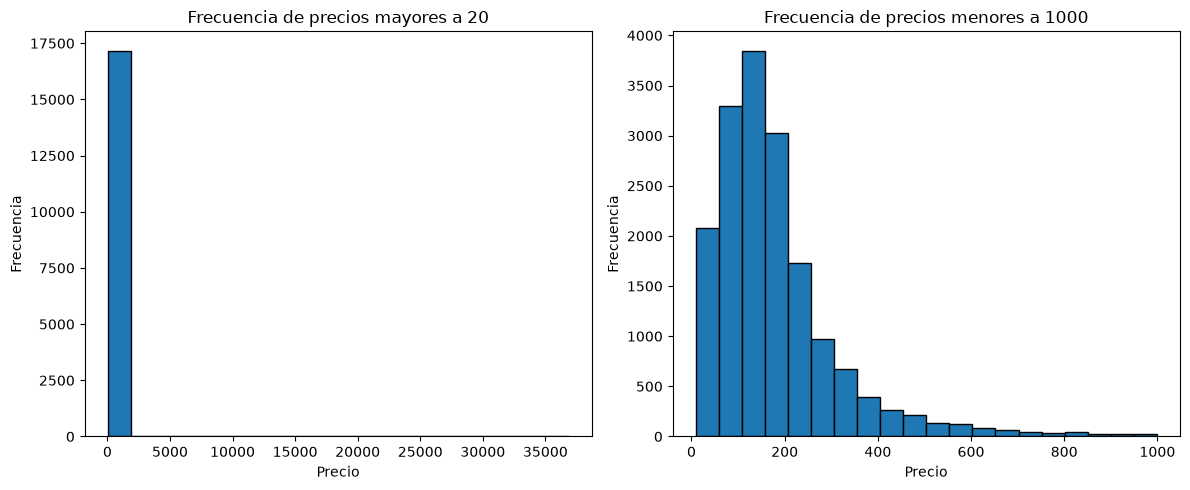

In [205]:
listings_price_menor_20 = listings.loc[listings["price"] > 20, "price"]
listings_price_mayor_1000 = listings.loc[listings["price"] < 1000, "price"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

listings_price_menor_20.plot.hist(bins=20, edgecolor="black", ax=axes[0])
axes[0].set_title("Frecuencia de precios mayores a 20")
axes[0].set_xlabel("Precio")
axes[0].set_ylabel("Frecuencia")

listings_price_mayor_1000.plot.hist(bins=20, edgecolor="black", ax=axes[1])
axes[1].set_title("Frecuencia de precios menores a 1000")
axes[1].set_xlabel("Precio")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [206]:
# quedarnos con filas con precio mayor de 20 y menor de 1000 

listings = listings[(listings['price'] >= 20) & (listings['price'] <= 1000)]


In [207]:
listings[['price', 'minimum_nights', 'availability_365']].describe().T

,count,mean,std,min,25%,50%,75%,max
price,17070.0,179.966139,136.449322,20.0,92.0,149.0,221.0,1000.0
minimum_nights,17070.0,7.531459,15.744694,1.0,1.0,2.0,4.0,365.0
availability_365,17070.0,202.840305,121.430493,0.0,85.0,235.0,316.0,365.0


In [208]:
listings_det.info()

<class 'pandas.DataFrame'>
RangeIndex: 23109 entries, 0 to 23108
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            23109 non-null  int64  
 1   listing_url                                   23109 non-null  str    
 2   scrape_id                                     23109 non-null  int64  
 3   last_scraped                                  23109 non-null  str    
 4   source                                        6025 non-null   str    
 5   name                                          23109 non-null  str    
 6   description                                   22965 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   23108 non-null  str    
 9   host_id                                       23109 non-null  int64  
 1

In [209]:
columnas_a_incluir = ['id', 
                      'description', 
                      'accommodates',
                      'bathrooms', 
                      'bedrooms',
                      'beds', 
                      'review_scores_location',  
                      'estimated_occupancy_l365d']

listings_det = listings_det[columnas_a_incluir]

In [210]:
listings_det.info()

<class 'pandas.DataFrame'>
RangeIndex: 23109 entries, 0 to 23108
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         23109 non-null  int64  
 1   description                22965 non-null  str    
 2   accommodates               23109 non-null  int64  
 3   bathrooms                  0 non-null      float64
 4   bedrooms                   23097 non-null  float64
 5   beds                       22535 non-null  float64
 6   review_scores_location     19293 non-null  float64
 7   estimated_occupancy_l365d  23109 non-null  int64  
dtypes: float64(4), int64(3), str(1)
memory usage: 1.4 MB


In [211]:
# analisis de nulos en listings_det
listings_det.isnull().sum()

id                               0
description                    144
accommodates                     0
bathrooms                    23109
bedrooms                        12
beds                           574
review_scores_location        3816
estimated_occupancy_l365d        0
dtype: int64

In [212]:
(listings_det["estimated_occupancy_l365d"] == 0).sum()

np.int64(6994)

In [213]:
registros_eliminados = listings_det["estimated_occupancy_l365d"].eq(0).sum()
listings_det = listings_det.loc[listings_det["estimated_occupancy_l365d"].ne(0)].copy()
print(f"Registros eliminados: {registros_eliminados}")
print(f"Registros restantes: {len(listings_det)}")

Registros eliminados: 6994
Registros restantes: 16115


In [214]:
listings_det.isnull().sum()

id                               0
description                     16
accommodates                     0
bathrooms                    16115
bedrooms                         9
beds                           408
review_scores_location           0
estimated_occupancy_l365d        0
dtype: int64

In [215]:
#eliminar registros con accomodates mayores que 8
listings_det = listings_det.loc[listings_det["accommodates"] <= 8].copy()


In [216]:
listings_det = listings_det.loc[listings_det["bedrooms"] <= 8].copy()


In [217]:
listings_det = listings_det.loc[listings_det["bedrooms"] > 0].copy()


In [218]:
listings_det = listings_det.loc[listings_det["beds"] <= 6].copy()


In [219]:
listings_det.isnull().sum()

id                               0
description                     10
accommodates                     0
bathrooms                    14218
bedrooms                         0
beds                             0
review_scores_location           0
estimated_occupancy_l365d        0
dtype: int64

In [220]:
listings_det.shape

(14218, 8)

In [221]:
listings_det.info()

<class 'pandas.DataFrame'>
Index: 14218 entries, 1 to 23106
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         14218 non-null  int64  
 1   description                14208 non-null  str    
 2   accommodates               14218 non-null  int64  
 3   bathrooms                  0 non-null      float64
 4   bedrooms                   14218 non-null  float64
 5   beds                       14218 non-null  float64
 6   review_scores_location     14218 non-null  float64
 7   estimated_occupancy_l365d  14218 non-null  int64  
dtypes: float64(4), int64(3), str(1)
memory usage: 999.7 KB


toca imputar a mano por numero de habitaciones el numero de baños aprox que tendría ese piso

In [222]:
listings_det.bedrooms.unique()

array([1., 2., 3., 4., 5., 8., 6.])

In [223]:
#código que impute numero de baños (int64) según el numero de bedrooms: entre 1 y 2 bedrooms, 1 bathrooms, entre 3 y 5 bedrooms, 2 bathrooms, entre 6 y 8 bedrooms, 3 bathrooms

baños_por_dormitorios = {
    1: 1, 2: 1,
    3: 2, 4: 2, 5: 2,
    6: 3, 7: 3, 8: 3
}

sin_baños = listings_det["bathrooms"].isna()
listings_det.loc[sin_baños, "bathrooms"] = (
    listings_det.loc[sin_baños, "bedrooms"].map(baños_por_dormitorios)
)

# Mantiene los valores desconocidos como nulos y usa un tipo entero
listings_det["bathrooms"] = listings_det["bathrooms"].astype("int64")

In [224]:
listings_det.isnull().sum()

id                            0
description                  10
accommodates                  0
bathrooms                     0
bedrooms                      0
beds                          0
review_scores_location        0
estimated_occupancy_l365d     0
dtype: int64

In [232]:
listings_det.to_csv(
    r"datos\procesados\listings_det.csv",
    index=False,
    encoding="utf-8-sig"
)


In [225]:
pd.crosstab(listings_det.accommodates, listings_det.bedrooms)

bedrooms,1.0,2.0,3.0,4.0,5.0,6.0,8.0
accommodates,,,,,,,
1,1198,26,6,6,9,1,1
2,4673,53,5,6,2,2,0
3,1093,381,21,0,0,0,0
4,2408,1601,71,4,0,0,0
5,88,446,188,5,1,0,0
6,86,806,524,33,3,3,0
7,11,27,84,35,1,1,0
8,10,41,157,97,4,0,0


In [226]:
listings_det.duplicated().sum()

np.int64(0)

## carga datos externo idealista del precio metros cuadrados


In [227]:
euros_m2 = pd.read_csv(
    Path(r"datos\brutos\euros_m2_madrid.csv"),
    header=0,
    names=["price_m2", "neighbourhood_group"]
)

# Excluir la fila del precio general, que no tiene barrio
euros_m2 = euros_m2.dropna(subset=["neighbourhood_group"]).copy()

# Convertir precios como "6.458 €/m2" a números enteros como 6458
euros_m2["price_m2"] = (
    euros_m2["price_m2"]
    .str.replace(" €/m2", "", regex=False)
    .str.replace(".", "", regex=False)
    .astype("int64")
)

euros_m2

,price_m2,neighbourhood_group
1,6384,Arganzuela
2,4971,Barajas
3,10865,Barrio de Salamanca
4,3829,Carabanchel
5,7771,Centro
6,8127,Chamartín
7,9159,Chamberí
8,5242,Ciudad Lineal
9,5593,Fuencarral
10,5440,Hortaleza


In [228]:
distritos_idealista = euros_m2.neighbourhood_group.unique()
distritos_idealista

<StringArray>
[         'Arganzuela',             'Barajas', 'Barrio de Salamanca',
         'Carabanchel',              'Centro',           'Chamartín',
            'Chamberí',       'Ciudad Lineal',          'Fuencarral',
           'Hortaleza',              'Latina',             'Moncloa',
           'Moratalaz',  'Puente de Vallecas',              'Retiro',
            'San Blas',              'Tetuán',               'Usera',
           'Vicálvaro',   'Villa de Vallecas',          'Villaverde']
Length: 21, dtype: str

In [229]:
distritos_listings = listings.neighbourhood_group.unique()
distritos_listings

<StringArray>
[               'Centro',             'Salamanca',              'Chamberí',
           'Carabanchel',             'Hortaleza',                 'Usera',
                'Latina',            'Arganzuela',                'Retiro',
         'Ciudad Lineal',                'Tetuán',             'Chamartín',
    'Puente de Vallecas', 'Fuencarral - El Pardo',     'Moncloa - Aravaca',
 'San Blas - Canillejas',               'Barajas',            'Villaverde',
             'Moratalaz',     'Villa de Vallecas',             'Vicálvaro']
Length: 21, dtype: str

In [230]:
# Unificar los nombres de listings con los de euros_m2
equivalencias_distritos = {
    "Salamanca": "Barrio de Salamanca",
    "Fuencarral - El Pardo": "Fuencarral",
    "Moncloa - Aravaca": "Moncloa",
    "San Blas - Canillejas": "San Blas",
}

listings["neighbourhood_group"] = listings["neighbourhood_group"].replace(
    equivalencias_distritos
)

# Comprobar que todos los distritos de listings existen en euros_m2
distritos_sin_match = sorted(
    set(listings["neighbourhood_group"].dropna())
    - set(euros_m2["neighbourhood_group"].dropna())
)

if distritos_sin_match:
    raise ValueError(f"Distritos de listings sin correspondencia: {distritos_sin_match}")

# Añadir price_m2 conservando todos los registros de listings
filas_originales = len(listings)

listings = listings.merge(
    euros_m2[["neighbourhood_group", "price_m2"]],
    on="neighbourhood_group",
    how="left",
    validate="many_to_one",
)

if len(listings) != filas_originales:
    raise ValueError("El merge ha cambiado el número de filas de listings.")

In [231]:
listings.isna().sum()

id                     0
name                   0
neighbourhood_group    0
neighbourhood          0
latitude               0
longitude              0
room_type              0
price                  0
minimum_nights         0
availability_365       0
price_m2               0
dtype: int64

In [233]:
listings.to_csv(
    r"datos\procesados\listings_con_price_m2.csv",
    index=False,
    encoding="utf-8-sig"
)


In [235]:
import sqlite3
from pathlib import Path

ruta_db = Path(r"datos\intermedios\inmobiliario.sqlite")
ruta_db.parent.mkdir(parents=True, exist_ok=True)


def identificador_sql(nombre):
    """Escapa nombres de tablas y columnas para SQLite."""
    return '"' + str(nombre).replace('"', '""') + '"'


def tipo_sqlite(tipo):
    if pd.api.types.is_bool_dtype(tipo) or pd.api.types.is_integer_dtype(tipo):
        return "INTEGER"
    if pd.api.types.is_float_dtype(tipo):
        return "REAL"
    if pd.api.types.is_datetime64_any_dtype(tipo):
        return "TEXT"
    return "TEXT"


def crear_tabla(conn, nombre, df, clave_primaria=None, columnas_unicas=(), claves_foraneas=()):
    definiciones = []

    for columna, tipo in df.dtypes.items():
        definicion = f"{identificador_sql(columna)} {tipo_sqlite(tipo)}"

        if columna == clave_primaria:
            definicion += " PRIMARY KEY"
        if columna in columnas_unicas:
            definicion += " UNIQUE"

        definiciones.append(definicion)

    for columna, tabla_referenciada, columna_referenciada in claves_foraneas:
        definiciones.append(
            f"FOREIGN KEY ({identificador_sql(columna)}) "
            f"REFERENCES {identificador_sql(tabla_referenciada)} "
            f"({identificador_sql(columna_referenciada)})"
        )

    sql = (
        f"CREATE TABLE {identificador_sql(nombre)} "
        f"({', '.join(definiciones)})"
    )
    conn.execute(sql)


# Comprobar que las claves puedan identificar registros de forma única.
if listings["id"].duplicated().any():
    raise ValueError("listings contiene valores duplicados en la columna 'id'.")

if euros_m2["neighbourhood_group"].duplicated().any():
    raise ValueError(
        "euros_m2 contiene valores duplicados en 'neighbourhood_group'."
    )


with sqlite3.connect(ruta_db) as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    # Se crean e insertan primero las tablas referenciadas.
    crear_tabla(
        conn,
        "euros_m2",
        euros_m2,
        columnas_unicas=("neighbourhood_group",),
    )
    euros_m2.to_sql("euros_m2", conn, if_exists="append", index=False)

    crear_tabla(
        conn,
        "listings",
        listings,
        clave_primaria="id",
        claves_foraneas=(
            ("neighbourhood_group", "euros_m2", "neighbourhood_group"),
        ),
    )
    listings.to_sql("listings", conn, if_exists="append", index=False)

    crear_tabla(
        conn,
        "listings_det",
        listings_det,
        claves_foraneas=(("id", "listings", "id"),),
    )
    listings_det.to_sql("listings_det", conn, if_exists="append", index=False)

    errores_fk = conn.execute("PRAGMA foreign_key_check").fetchall()
    if errores_fk:
        raise sqlite3.IntegrityError(
            f"Se han encontrado errores en las claves foráneas: {errores_fk[:10]}"
        )

print(f"Base de datos creada correctamente en: {ruta_db}")

DatabaseError: Execution failed